# 🧠 Modeling TabNet — Multi-Output Classification
### Dataset: Status Gizi Balita — Kabupaten Jeneponto (2021–2024)

---

| Keterangan | Detail |
|---|---|
| **Nama Mahasiswa** | Sherlly Briliant Saputri |
| **NIM** | 5230411156 |
| **Program Studi** | Informatika |
| **Universitas** | Universitas Teknologi Yogyakarta |
| **Model** | TabNet (Attentive Mechanism) |
| **Tuning** | Optuna Bayesian Optimization |

---

**Target Output — Multi-Output Classification (3 label):**
- **Weight for Age (BB/U)** — 4 kelas: Underfed, Normal, Malnutrition, Overnutrition
- **Height for Age (TB/U)** — 2 kelas: Not Stunted, Stunted
- **Weight for Height (BB/TB)** — 4 kelas: Very Thin, Thin, Normal, Obese

**Alasan n_trials Optuna:**
> `n_trials=30` dipilih sebagai keseimbangan optimal antara eksplorasi ruang hiperparameter dan efisiensi komputasi. TabNet memiliki 5 hiperparameter kunci (lr, n_d, n_a, n_steps, gamma) dengan ruang pencarian luas; 30 trial sudah cukup untuk menemukan kombinasi yang baik menggunakan Bayesian TPE Sampler — jauh lebih efisien dibanding Grid Search yang membutuhkan ratusan kombinasi.

## 📦 1. Import Library

In [2]:
# ─── Standard Library ───────────────────────────────────────────────────────
import warnings
import os
import time
from datetime import datetime
warnings.filterwarnings('ignore')

# ─── Data Manipulation ──────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ─── Visualization ──────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ─── Machine Learning — Evaluasi ────────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

# ─── TabNet ──────────────────────────────────────────────────────────────────
!pip install pytorch-tabnet
from pytorch_tabnet.tab_model import TabNetClassifier

# ─── Optuna (Bayesian Optimization) ─────────────────────────────────────────
!pip install optuna
import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ─── Serialisasi ─────────────────────────────────────────────────────────────
import joblib

# ─── Plot Style ───────────────────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
COLORS = {
    'primary'  : '#2196F3',
    'secondary': '#FF5722',
    'accent'   : '#4CAF50',
    'warning'  : '#FF9800',
    'purple'   : '#9C27B0',
    'teal'     : '#009688'
}

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('✅ Library berhasil diimport!')
print(f'   pandas  : {pd.__version__}')
print(f'   numpy   : {np.__version__}')
print(f'   optuna  : {optuna.__version__}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 8.3 MB/s eta 0:00:00
✅ Library berhasil diimport!
   pandas  : 2.2.2
   numpy   : 2.0.2
   optuna  : 4.8.0


## 📂 2. Load Data

In [3]:
# ─── Load Data Hasil Preprocessing ──────────────────────────────────────────
# Data sudah di-scale (StandardScaler) dan training sudah di-SMOTE-NC
df_train = pd.read_csv('train_smote.csv')
df_test  = pd.read_csv('test.csv')

print('✅ Data berhasil dimuat!')
print(f'   Train [SMOTE+Scaled]: {df_train.shape[0]:,} baris × {df_train.shape[1]} kolom')
print(f'   Test  [Orig+Scaled] : {df_test.shape[0]:,} baris × {df_test.shape[1]} kolom')
print()
print('📌 Kolom:', list(df_train.columns))
print()
df_train.head()

✅ Data berhasil dimuat!
   Train [SMOTE+Scaled]: 85,851 baris × 7 kolom
   Test  [Orig+Scaled] : 10,662 baris × 7 kolom

📌 Kolom: ['Gender', 'Age (Month)', 'Weight', 'Height', 'Weight for Age', 'Height for Age', 'Weight for Height']



,Gender,Age (Month),Weight,Height,Weight for Age,Height for Age,Weight for Height
0,1,-0.821296,-0.534522,-1.215087,1,1,2
1,1,1.197115,1.313095,1.401499,1,0,2
2,1,-0.505919,-0.386712,-0.624245,1,1,2
3,1,-0.947446,-1.088807,-0.928107,0,1,2
4,1,-1.515125,-1.458330,-1.637117,1,1,2


## ⚙️ 3. Preprocessing (Pemisahan Fitur & Target)

In [4]:
# ─── Definisi Kolom ──────────────────────────────────────────────────────────
FEATURE_COLS = ['Gender', 'Age (Month)', 'Weight', 'Height']
TARGET_COLS  = ['Weight for Age', 'Height for Age', 'Weight for Height']

ENCODING_MAP = {
    'Weight for Age'   : {0: 'Underfed', 1: 'Normal', 2: 'Malnutrition', 3: 'Overnutrition'},
    'Height for Age'   : {0: 'Not Stunted', 1: 'Stunted'},
    'Weight for Height': {0: 'Very Thin', 1: 'Thin', 2: 'Normal', 3: 'Obese'}
}

# ─── Pisahkan Fitur dan Target ───────────────────────────────────────────────
X_train = df_train[FEATURE_COLS].values.astype(np.float32)
y_train = df_train[TARGET_COLS].values.astype(int)

X_test  = df_test[FEATURE_COLS].values.astype(np.float32)
y_test  = df_test[TARGET_COLS].values.astype(int)

# ─── Jumlah Kelas per Target ─────────────────────────────────────────────────
print('📌 Jumlah kelas per target:')
for i, col in enumerate(TARGET_COLS):
    n_cls = len(np.unique(y_train[:, i]))
    print(f'   {col}: {n_cls} kelas → {list(ENCODING_MAP[col].values())}')

print()
print(f'X_train: {X_train.shape}  |  y_train: {y_train.shape}')
print(f'X_test : {X_test.shape}  |  y_test : {y_test.shape}')

📌 Jumlah kelas per target:
   Weight for Age: 4 kelas → ['Underfed', 'Normal', 'Malnutrition', 'Overnutrition']
   Height for Age: 2 kelas → ['Not Stunted', 'Stunted']
   Weight for Height: 4 kelas → ['Very Thin', 'Thin', 'Normal', 'Obese']

X_train: (85851, 4)  |  y_train: (85851, 3)
X_test : (10662, 4)  |  y_test : (10662, 3)


In [5]:
# ─── Verifikasi Distribusi Kelas ─────────────────────────────────────────────
print('📊 Distribusi kelas (Training setelah SMOTE-NC):')
for i, col in enumerate(TARGET_COLS):
    unique, counts = np.unique(y_train[:, i], return_counts=True)
    print(f'\n  [{col}]')
    for k, v in zip(unique, counts):
        label = ENCODING_MAP[col].get(int(k), str(k))
        bar = '█' * int(v / len(y_train) * 40)
        print(f'    {k} [{label:<15}]: {v:>7,} ({v/len(y_train)*100:.2f}%) {bar}')

📊 Distribusi kelas (Training setelah SMOTE-NC):

  [Weight for Age]
    0 [Underfed       ]:  23,064 (26.87%) ██████████
    1 [Normal         ]:  32,035 (37.31%) ██████████████
    2 [Malnutrition   ]:  19,220 (22.39%) ████████
    3 [Overnutrition  ]:  11,532 (13.43%) █████

  [Height for Age]
    0 [Not Stunted    ]:  51,255 (59.70%) ███████████████████████
    1 [Stunted        ]:  34,596 (40.30%) ████████████████

  [Weight for Height]
    0 [Very Thin      ]:  15,376 (17.91%) ███████
    1 [Thin           ]:  19,220 (22.39%) ████████
    2 [Normal         ]:  32,035 (37.31%) ██████████████
    3 [Obese          ]:  19,220 (22.39%) ████████


## 🔬 4. Modeling + Optuna (Bayesian Optimization)

**Strategi:** TabNet tidak mendukung multi-output secara native, sehingga dibuat **3 model terpisah** — satu per label target. Setiap model di-tune independen menggunakan Optuna.

**Hiperparameter yang di-tune:**
| Parameter | Rentang | Keterangan |
|---|---|---|
| `learning_rate` | 1e-4 – 1e-1 (log) | Laju pembelajaran Adam |
| `n_d` | 8 – 64 (step 8) | Dimensi representasi di tiap step |
| `n_a` | 8 – 64 (step 8) | Dimensi attention embedding |
| `n_steps` | 3 – 10 | Jumlah sequential attention steps |
| `gamma` | 1.0 – 2.0 | Koefisien relaxation untuk feature reusage |

In [6]:
# ─── Fungsi Objective Optuna per Label ──────────────────────────────────────
def make_objective(label_idx, X_tr, y_tr, X_te, y_te):
    """Membuat fungsi objective untuk satu label target."""
    y_tr_single = y_tr[:, label_idx]
    y_te_single = y_te[:, label_idx]

    def objective(trial):
        params = {
            'n_d'          : trial.suggest_int('n_d', 8, 64, step=8),
            'n_a'          : trial.suggest_int('n_a', 8, 64, step=8),
            'n_steps'      : trial.suggest_int('n_steps', 3, 10),
            'gamma'        : trial.suggest_float('gamma', 1.0, 2.0, step=0.1),
            'learning_rate': trial.suggest_float('learning_rate', 1e-4, 1e-1, log=True),
            'momentum'     : trial.suggest_float('momentum', 0.01, 0.4),
        }

        model = TabNetClassifier(
            n_d              = params['n_d'],
            n_a              = params['n_a'],
            n_steps          = params['n_steps'],
            gamma            = params['gamma'],
            optimizer_params = {'lr': params['learning_rate']},
            momentum         = params['momentum'],
            verbose          = 0,
            seed             = RANDOM_STATE,
        )

        model.fit(
            X_tr, y_tr_single,
            eval_set           = [(X_te, y_te_single)],
            eval_metric        = ['accuracy'],
            max_epochs         = 100,
            patience           = 10,
            batch_size         = 1024,
            virtual_batch_size = 256,
            drop_last          = False,
        )

        y_pred = model.predict(X_te)
        return f1_score(y_te_single, y_pred, average='weighted', zero_division=0)

    return objective


# ─── Jalankan Optuna untuk Setiap Label ─────────────────────────────────────
# n_trials=30: keseimbangan eksplorasi vs efisiensi untuk 5 hiperparameter TabNet
N_TRIALS = 30
best_params_all = {}
study_results   = {}

for i, label in enumerate(TARGET_COLS):
    print(f'\n{"="*60}')
    print(f'🔍 Optuna Tuning: [{label}] — {N_TRIALS} trials')
    print(f'{"="*60}')

    study = optuna.create_study(
        direction  = 'maximize',
        sampler    = TPESampler(seed=RANDOM_STATE),
        study_name = f'tabnet_{label.replace(" ", "_").lower()}'
    )

    study.optimize(
        make_objective(i, X_train, y_train, X_test, y_test),
        n_trials           = N_TRIALS,
        show_progress_bar  = True
    )

    best_params_all[label] = study.best_params
    study_results[label]   = study

    print(f'\n✅ Best Weighted F1 : {study.best_value:.4f}')
    for k, v in study.best_params.items():
        print(f'   {k:<20}: {v}')

print('\n✅ Optuna tuning selesai untuk semua label!')


🔍 Optuna Tuning: [Weight for Age] — 30 trials


  0%|          | 0/30 [00:00<?, ?it/s]


Early stopping occurred at epoch 37 with best_epoch = 27 and best_val_0_accuracy = 0.9532

Early stopping occurred at epoch 66 with best_epoch = 56 and best_val_0_accuracy = 0.94044

Early stopping occurred at epoch 30 with best_epoch = 20 and best_val_0_accuracy = 0.95723

Early stopping occurred at epoch 28 with best_epoch = 18 and best_val_0_accuracy = 0.95564

Early stopping occurred at epoch 20 with best_epoch = 10 and best_val_0_accuracy = 0.95536

Early stopping occurred at epoch 36 with best_epoch = 26 and best_val_0_accuracy = 0.95461

Early stopping occurred at epoch 84 with best_epoch = 74 and best_val_0_accuracy = 0.9501

Early stopping occurred at epoch 33 with best_epoch = 23 and best_val_0_accuracy = 0.95854

Early stopping occurred at epoch 19 with best_epoch = 9 and best_val_0_accuracy = 0.95498

Early stopping occurred at epoch 24 with best_epoch = 14 and best_val_0_accuracy = 0.94007

Early stopping occurred at epoch 17 with best_epoch = 7 and best_val_0_accuracy = 

  0%|          | 0/30 [00:00<?, ?it/s]


Early stopping occurred at epoch 50 with best_epoch = 40 and best_val_0_accuracy = 0.95245

Early stopping occurred at epoch 68 with best_epoch = 58 and best_val_0_accuracy = 0.94757

Early stopping occurred at epoch 28 with best_epoch = 18 and best_val_0_accuracy = 0.95667

Early stopping occurred at epoch 28 with best_epoch = 18 and best_val_0_accuracy = 0.95639

Early stopping occurred at epoch 23 with best_epoch = 13 and best_val_0_accuracy = 0.95451

Early stopping occurred at epoch 20 with best_epoch = 10 and best_val_0_accuracy = 0.95592

Early stopping occurred at epoch 48 with best_epoch = 38 and best_val_0_accuracy = 0.94466

Early stopping occurred at epoch 38 with best_epoch = 28 and best_val_0_accuracy = 0.95414

Early stopping occurred at epoch 12 with best_epoch = 2 and best_val_0_accuracy = 0.94316

Early stopping occurred at epoch 40 with best_epoch = 30 and best_val_0_accuracy = 0.95526

Early stopping occurred at epoch 26 with best_epoch = 16 and best_val_0_accuracy

  0%|          | 0/30 [00:00<?, ?it/s]


Early stopping occurred at epoch 59 with best_epoch = 49 and best_val_0_accuracy = 0.97515

Early stopping occurred at epoch 14 with best_epoch = 4 and best_val_0_accuracy = 0.84881

Early stopping occurred at epoch 20 with best_epoch = 10 and best_val_0_accuracy = 0.9758

Early stopping occurred at epoch 49 with best_epoch = 39 and best_val_0_accuracy = 0.9803

Early stopping occurred at epoch 36 with best_epoch = 26 and best_val_0_accuracy = 0.98124

Early stopping occurred at epoch 22 with best_epoch = 12 and best_val_0_accuracy = 0.9803

Early stopping occurred at epoch 60 with best_epoch = 50 and best_val_0_accuracy = 0.96314

Early stopping occurred at epoch 42 with best_epoch = 32 and best_val_0_accuracy = 0.97665

Early stopping occurred at epoch 30 with best_epoch = 20 and best_val_0_accuracy = 0.9744

Early stopping occurred at epoch 57 with best_epoch = 47 and best_val_0_accuracy = 0.97636

Early stopping occurred at epoch 28 with best_epoch = 18 and best_val_0_accuracy = 0

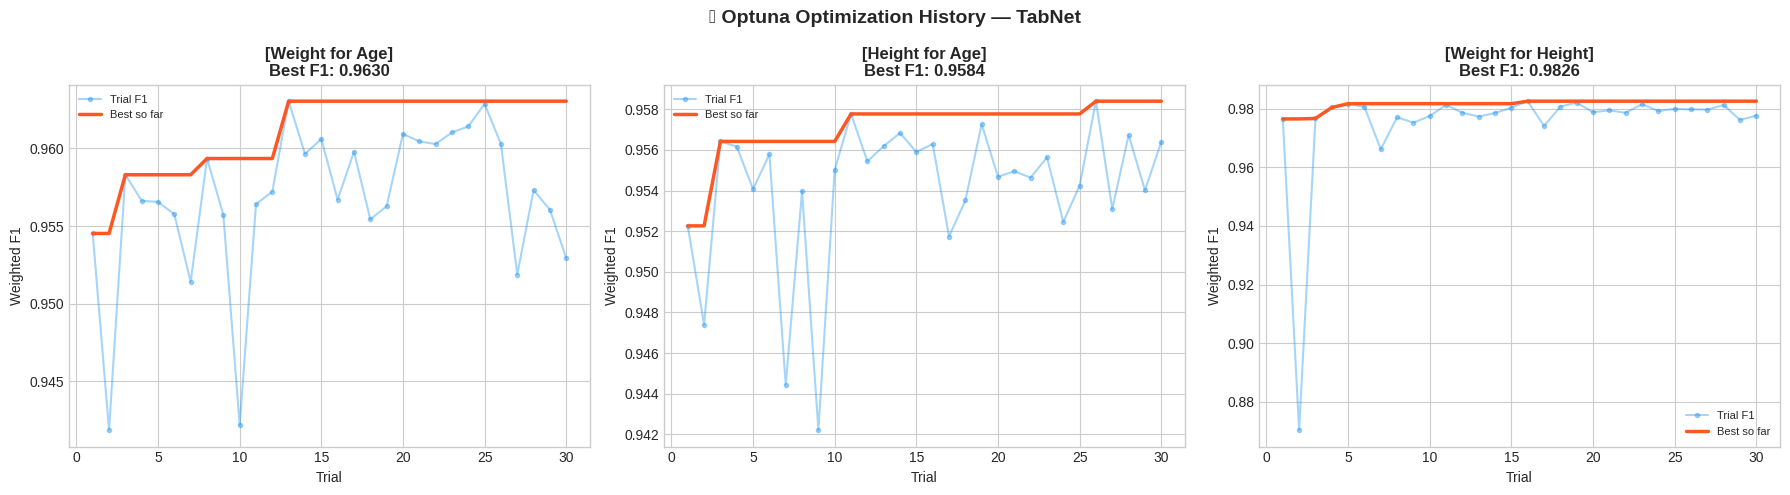

✅ Optuna history tersimpan: tabnet_optuna_history.png


In [7]:
# ─── Visualisasi Optuna: Optimization History ────────────────────────────────
fig, axes = plt.subplots(1, len(TARGET_COLS), figsize=(18, 5))
fig.suptitle('📈 Optuna Optimization History — TabNet', fontsize=14, fontweight='bold')

for ax, (label, study) in zip(axes, study_results.items()):
    values = [t.value for t in study.trials if t.value is not None]
    best_vals = [max(values[:i+1]) for i in range(len(values))]

    ax.plot(range(1, len(values)+1), values,    alpha=0.4, color=COLORS['primary'],
            marker='o', markersize=3, label='Trial F1')
    ax.plot(range(1, len(best_vals)+1), best_vals, color=COLORS['secondary'],
            linewidth=2.5, label='Best so far')
    ax.set_title(f'[{label}]\nBest F1: {study.best_value:.4f}', fontweight='bold')
    ax.set_xlabel('Trial')
    ax.set_ylabel('Weighted F1')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('tabnet_optuna_history.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Optuna history tersimpan: tabnet_optuna_history.png')

## 🏋️ 5. Training Final Model

In [8]:
# ─── Training Final dengan Best Hyperparams ──────────────────────────────────
final_models     = {}
training_history = {}

for i, label in enumerate(TARGET_COLS):
    params       = best_params_all[label]
    y_tr_single  = y_train[:, i]
    y_te_single  = y_test[:, i]

    print(f'\n🏋️  Training final model: [{label}]')
    print(f'   Params: {params}')

    model = TabNetClassifier(
        n_d              = params['n_d'],
        n_a              = params['n_a'],
        n_steps          = params['n_steps'],
        gamma            = params['gamma'],
        optimizer_params = {'lr': params['learning_rate']},
        momentum         = params['momentum'],
        verbose          = 1,
        seed             = RANDOM_STATE,
    )

    model.fit(
        X_train, y_tr_single,
        eval_set           = [(X_train, y_tr_single), (X_test, y_te_single)],
        eval_name          = ['train', 'test'],
        eval_metric        = ['accuracy'],
        max_epochs         = 200,
        patience           = 20,
        batch_size         = 1024,
        virtual_batch_size = 256,
        drop_last          = False,
    )

    final_models[label]     = model
    training_history[label] = model.history
    print(f'  ✅ [{label}] selesai!')

print('\n✅ Semua final model selesai ditraining!')


🏋️  Training final model: [Weight for Age]
   Params: {'n_d': 64, 'n_a': 32, 'n_steps': 5, 'gamma': 1.0, 'learning_rate': 0.0011026511314900513, 'momentum': 0.20084517150524542}
epoch 0  | loss: 0.78718 | train_accuracy: 0.74808 | test_accuracy: 0.83033 |  0:00:06s
epoch 1  | loss: 0.24738 | train_accuracy: 0.87933 | test_accuracy: 0.923   |  0:00:11s
epoch 2  | loss: 0.20887 | train_accuracy: 0.93309 | test_accuracy: 0.94963 |  0:00:18s
epoch 3  | loss: 0.19554 | train_accuracy: 0.92691 | test_accuracy: 0.9395  |  0:00:23s
epoch 4  | loss: 0.18914 | train_accuracy: 0.94735 | test_accuracy: 0.94166 |  0:00:30s
epoch 5  | loss: 0.17933 | train_accuracy: 0.9494  | test_accuracy: 0.95189 |  0:00:35s
epoch 6  | loss: 0.17003 | train_accuracy: 0.9484  | test_accuracy: 0.94701 |  0:00:42s
epoch 7  | loss: 0.1632  | train_accuracy: 0.94531 | test_accuracy: 0.9426  |  0:00:48s
epoch 8  | loss: 0.16263 | train_accuracy: 0.96098 | test_accuracy: 0.94682 |  0:00:54s
epoch 9  | loss: 0.16123 | tr

## 📊 6. Evaluasi Training

In [9]:
# ─── Evaluasi pada Data Training ─────────────────────────────────────────────
print('='*70)
print('               📊 EVALUASI DATA TRAINING')
print('='*70)

train_results = {}
for i, label in enumerate(TARGET_COLS):
    y_pred_train = final_models[label].predict(X_train)
    y_true_train = y_train[:, i]

    acc  = accuracy_score(y_true_train, y_pred_train)
    f1_w = f1_score(y_true_train, y_pred_train, average='weighted', zero_division=0)
    f1_m = f1_score(y_true_train, y_pred_train, average='macro',    zero_division=0)

    train_results[label] = {'accuracy': acc, 'f1_weighted': f1_w, 'f1_macro': f1_m}

    print(f'\n[{label}]')
    print(f'  Accuracy    : {acc:.4f} ({acc*100:.2f}%)')
    print(f'  F1 Weighted : {f1_w:.4f}')
    print(f'  F1 Macro    : {f1_m:.4f}')

    label_names = [ENCODING_MAP[label][k] for k in sorted(ENCODING_MAP[label].keys())]
    print(classification_report(y_true_train, y_pred_train,
                                target_names=label_names, zero_division=0))

               📊 EVALUASI DATA TRAINING

[Weight for Age]
  Accuracy    : 0.9678 (96.78%)
  F1 Weighted : 0.9677
  F1 Macro    : 0.9688
               precision    recall  f1-score   support

     Underfed       0.95      0.94      0.95     23064
       Normal       0.98      0.98      0.98     32035
 Malnutrition       0.97      0.95      0.96     19220
Overnutrition       0.98      0.99      0.99     11532

     accuracy                           0.97     85851
    macro avg       0.97      0.97      0.97     85851
 weighted avg       0.97      0.97      0.97     85851


[Height for Age]
  Accuracy    : 0.9721 (97.21%)
  F1 Weighted : 0.9721
  F1 Macro    : 0.9710
              precision    recall  f1-score   support

 Not Stunted       0.98      0.98      0.98     51255
     Stunted       0.96      0.97      0.97     34596

    accuracy                           0.97     85851
   macro avg       0.97      0.97      0.97     85851
weighted avg       0.97      0.97      0.97     85851

## 🧪 7. Evaluasi Testing

In [10]:
# ─── Evaluasi pada Data Testing ──────────────────────────────────────────────
print('='*70)
print('               🧪 EVALUASI DATA TESTING')
print('='*70)

test_results = {}
for i, label in enumerate(TARGET_COLS):
    y_pred_test = final_models[label].predict(X_test)
    y_true_test = y_test[:, i]

    acc  = accuracy_score(y_true_test, y_pred_test)
    f1_w = f1_score(y_true_test, y_pred_test, average='weighted', zero_division=0)
    f1_m = f1_score(y_true_test, y_pred_test, average='macro',    zero_division=0)

    test_results[label] = {'accuracy': acc, 'f1_weighted': f1_w, 'f1_macro': f1_m}

    print(f'\n[{label}]')
    print(f'  Accuracy    : {acc:.4f} ({acc*100:.2f}%)')
    print(f'  F1 Weighted : {f1_w:.4f}')
    print(f'  F1 Macro    : {f1_m:.4f}')

    label_names = [ENCODING_MAP[label][k] for k in sorted(ENCODING_MAP[label].keys())]
    print(classification_report(y_true_test, y_pred_test,
                                target_names=label_names, zero_division=0))

# ─── Ringkasan Perbandingan ───────────────────────────────────────────────────
print('\n' + '─'*70)
print('📋 RINGKASAN: TRAIN vs TEST')
print('─'*70)
print(f'{"Label":<30} {"Acc Train":>10} {"Acc Test":>10} {"F1W Train":>10} {"F1W Test":>10}')
print('─'*70)
for label in TARGET_COLS:
    tr_acc = train_results[label]['accuracy']
    te_acc = test_results[label]['accuracy']
    tr_f1  = train_results[label]['f1_weighted']
    te_f1  = test_results[label]['f1_weighted']
    gap    = abs(tr_acc - te_acc)
    flag   = ' ⚠️ overfit' if gap > 0.05 else ' ✅'
    print(f'{label:<30} {tr_acc:>10.4f} {te_acc:>10.4f} {tr_f1:>10.4f} {te_f1:>10.4f}{flag}')

               🧪 EVALUASI DATA TESTING

[Weight for Age]
  Accuracy    : 0.9646 (96.46%)
  F1 Weighted : 0.9649
  F1 Macro    : 0.8875
               precision    recall  f1-score   support

     Underfed       0.91      0.88      0.90      1663
       Normal       0.98      0.98      0.98      8539
 Malnutrition       0.84      0.95      0.89       401
Overnutrition       0.67      0.93      0.78        59

     accuracy                           0.96     10662
    macro avg       0.85      0.94      0.89     10662
 weighted avg       0.97      0.96      0.96     10662


[Height for Age]
  Accuracy    : 0.9588 (95.88%)
  F1 Weighted : 0.9586
  F1 Macro    : 0.9540
              precision    recall  f1-score   support

 Not Stunted       0.96      0.98      0.97      6972
     Stunted       0.96      0.92      0.94      3690

    accuracy                           0.96     10662
   macro avg       0.96      0.95      0.95     10662
weighted avg       0.96      0.96      0.96     10662


## 🎯 8. Confusion Matrix (Train & Test)

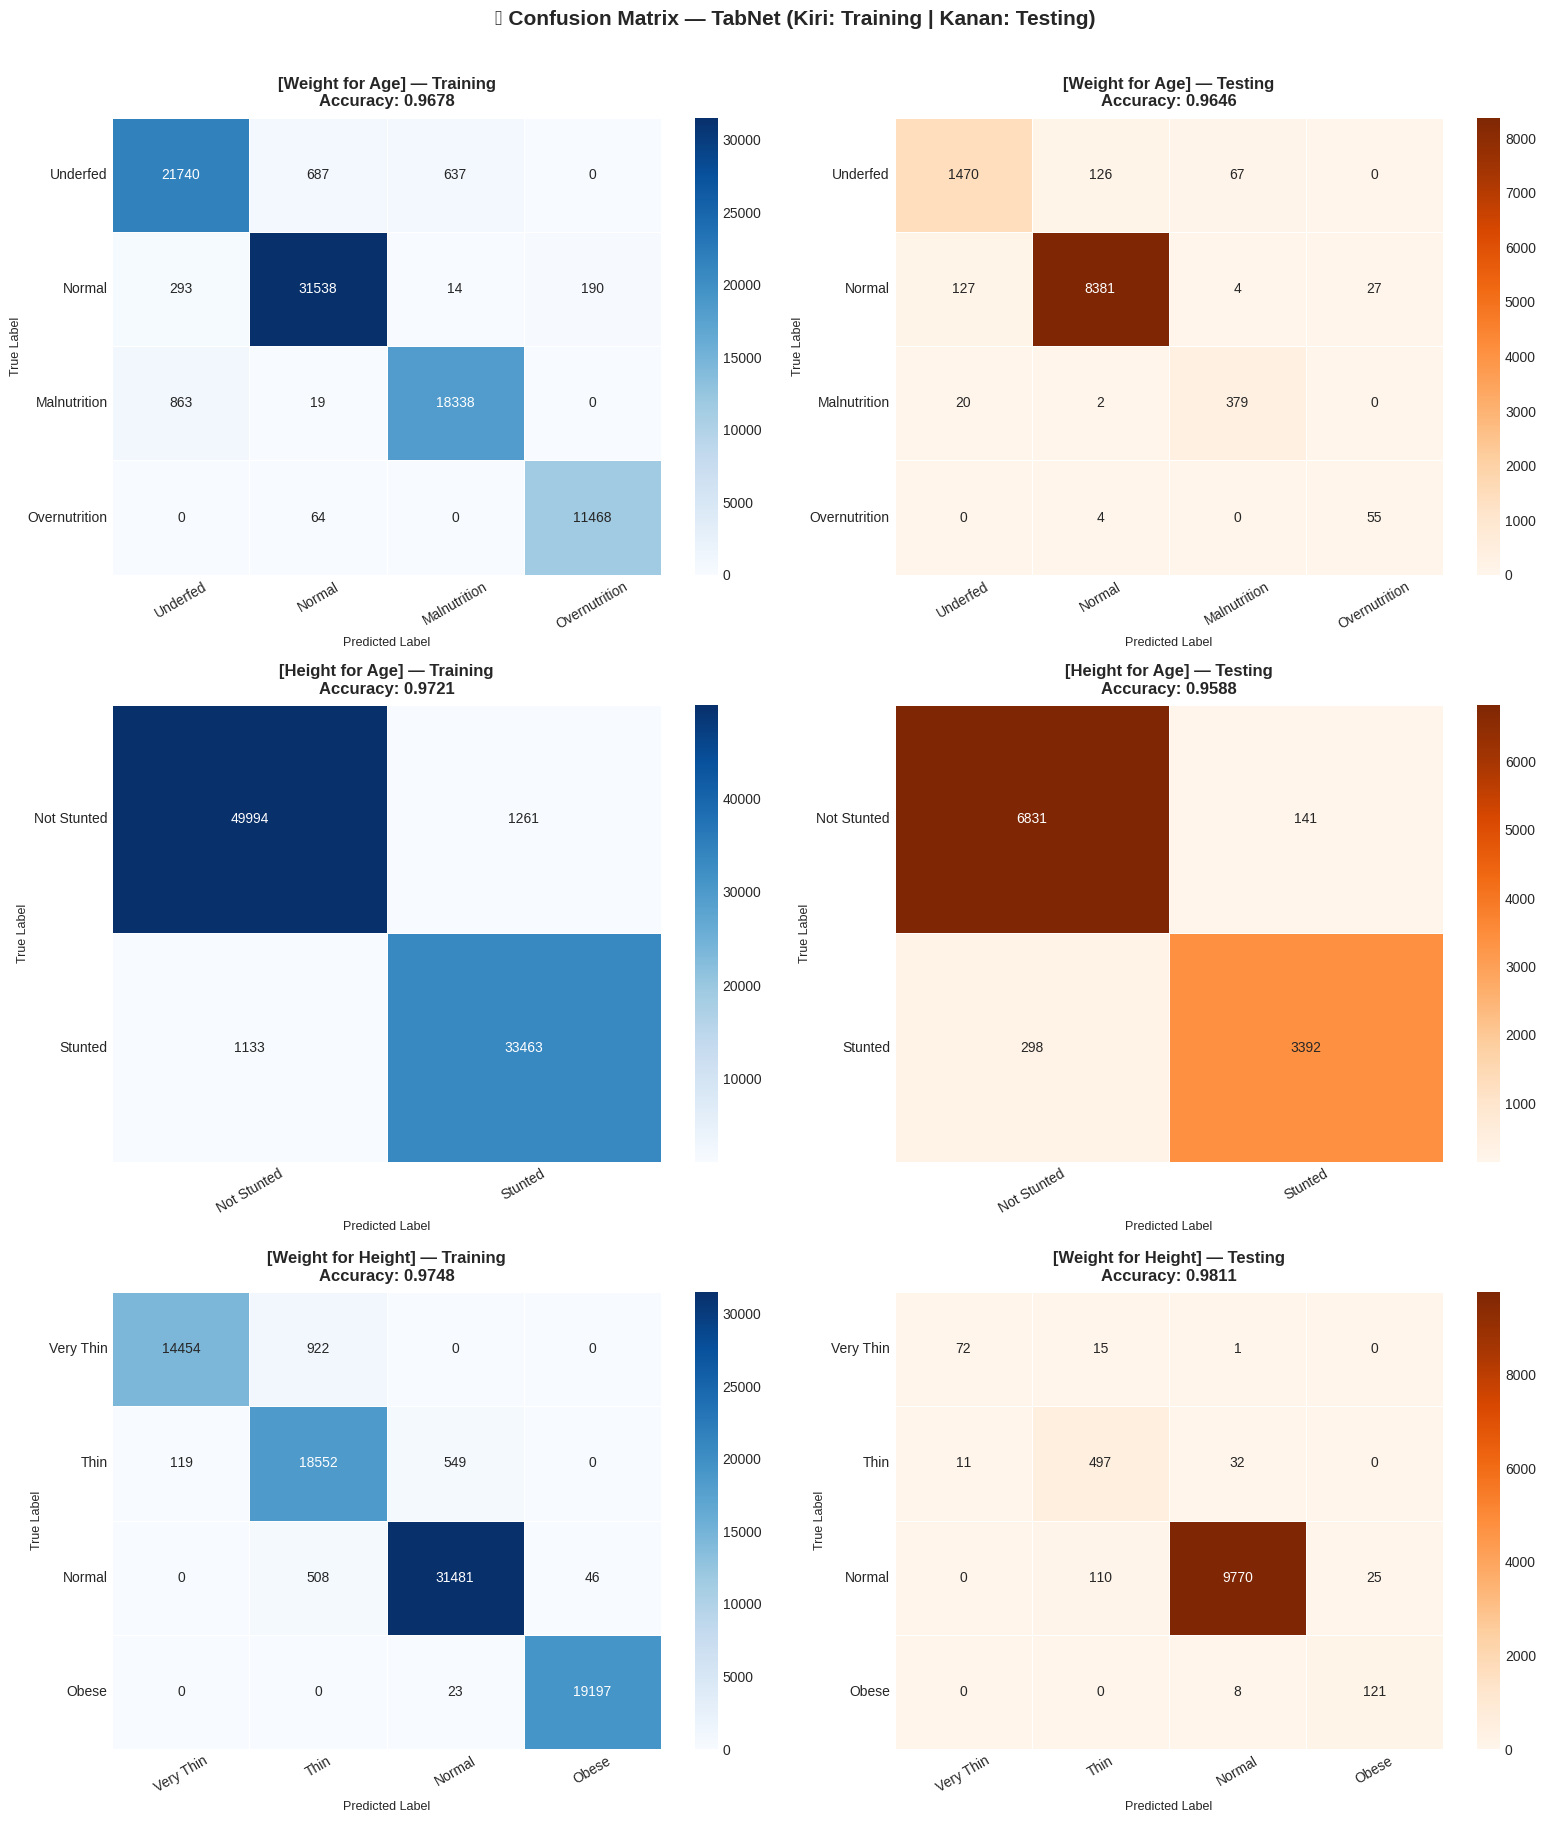

✅ Confusion matrix tersimpan: tabnet_confusion_matrix.png


In [11]:
# ─── Confusion Matrix — Semua Label, Train & Test ───────────────────────────
n_labels = len(TARGET_COLS)
fig, axes = plt.subplots(n_labels, 2, figsize=(16, 6 * n_labels))
fig.suptitle('🎯 Confusion Matrix — TabNet (Kiri: Training | Kanan: Testing)',
             fontsize=15, fontweight='bold', y=1.01)

for i, label in enumerate(TARGET_COLS):
    label_names = [ENCODING_MAP[label][k] for k in sorted(ENCODING_MAP[label].keys())]
    splits = [
        (X_train, y_train, 'Training', 'Blues'),
        (X_test,  y_test,  'Testing',  'Oranges')
    ]

    for j, (X_data, y_data, split_name, cmap) in enumerate(splits):
        y_pred = final_models[label].predict(X_data)
        y_true = y_data[:, i]
        cm     = confusion_matrix(y_true, y_pred)
        ax     = axes[i][j]

        sns.heatmap(cm, annot=True, fmt='d', ax=ax, cmap=cmap,
                    xticklabels=label_names, yticklabels=label_names,
                    linewidths=0.5, linecolor='white')

        acc = accuracy_score(y_true, y_pred)
        ax.set_title(f'[{label}] — {split_name}\nAccuracy: {acc:.4f}',
                     fontweight='bold', pad=8)
        ax.set_ylabel('True Label',      fontsize=9)
        ax.set_xlabel('Predicted Label', fontsize=9)
        ax.tick_params(axis='x', rotation=30)
        ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('tabnet_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Confusion matrix tersimpan: tabnet_confusion_matrix.png')

## 📈 9. Grafik Akurasi Training vs Testing

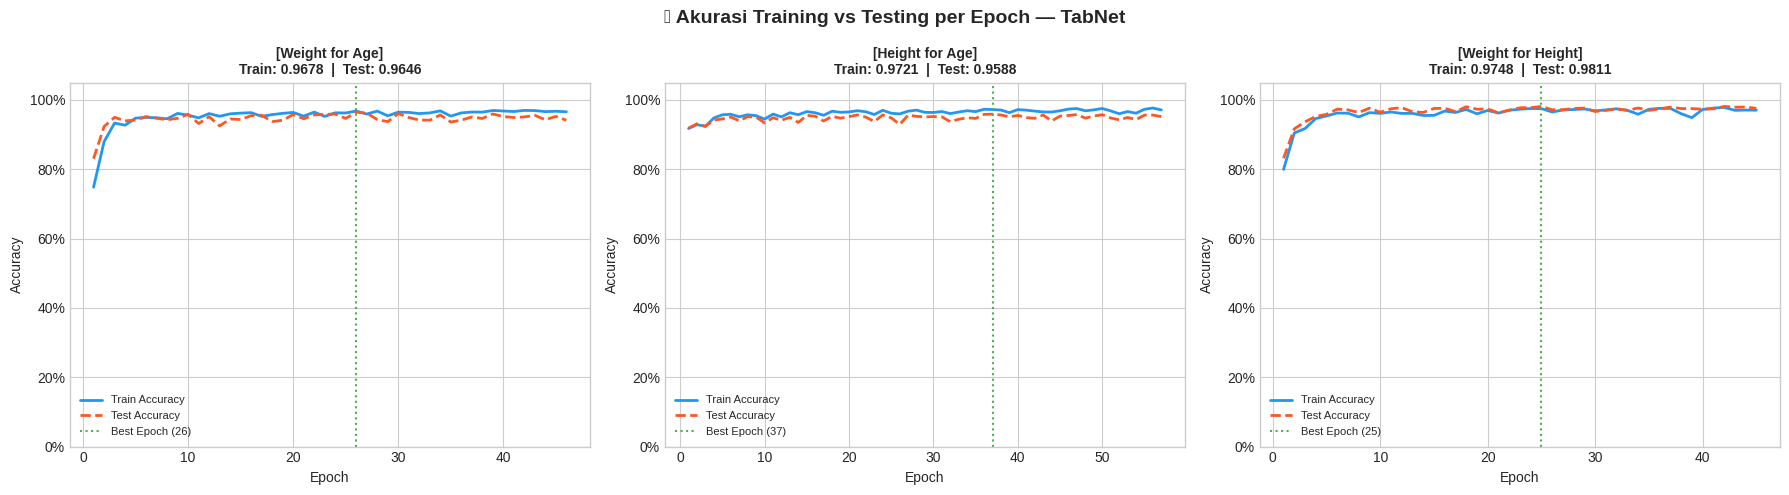

✅ Grafik akurasi tersimpan: tabnet_accuracy_curve.png


In [20]:
# ─── 1 Grafik: Akurasi Train vs Test per Label (per Epoch) ──────────────────
fig, axes = plt.subplots(1, len(TARGET_COLS), figsize=(18, 5))
fig.suptitle('📈 Akurasi Training vs Testing per Epoch — TabNet',
             fontsize=14, fontweight='bold')

for ax, label in zip(axes, TARGET_COLS):
    history = training_history[label]

    # 💡 PERBAIKAN: Ambil dictionary asli dari dalam objek History TabNet
    # Jika history adalah objek 'History', ambil .history-nya.
    # Jika sudah dictionary, gunakan langsung.
    hist_dict = history.history if hasattr(history, 'history') else history

    # Sekarang kita bisa menggunakan .get() dengan aman pada hist_dict
    train_acc = hist_dict.get('train_accuracy', hist_dict.get('train_acc', []))

    test_acc  = (hist_dict.get('test_accuracy', []) or
                 hist_dict.get('val_0_accuracy', []) or
                 hist_dict.get('valid_accuracy', []) or
                 hist_dict.get('test_acc', []))

    epochs = range(1, len(train_acc) + 1)

    ax.plot(epochs, train_acc, color=COLORS['primary'],
            linewidth=2, label='Train Accuracy')
    ax.plot(epochs, test_acc,  color=COLORS['secondary'],
            linewidth=2, linestyle='--', label='Test Accuracy')

    if len(test_acc) > 0:
        best_ep = int(np.argmax(test_acc)) + 1
        ax.axvline(best_ep, color=COLORS['accent'], linestyle=':',
                   linewidth=1.5, label=f'Best Epoch ({best_ep})')

    final_tr = train_results[label]['accuracy']
    final_te = test_results[label]['accuracy']
    ax.set_title(f'[{label}]\nTrain: {final_tr:.4f}  |  Test: {final_te:.4f}',
                 fontweight='bold', fontsize=10)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend(fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))

plt.tight_layout()
plt.savefig('tabnet_accuracy_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Grafik akurasi tersimpan: tabnet_accuracy_curve.png')

## 🔍 10. Feature Importance (TabNet Attentive Mechanism)

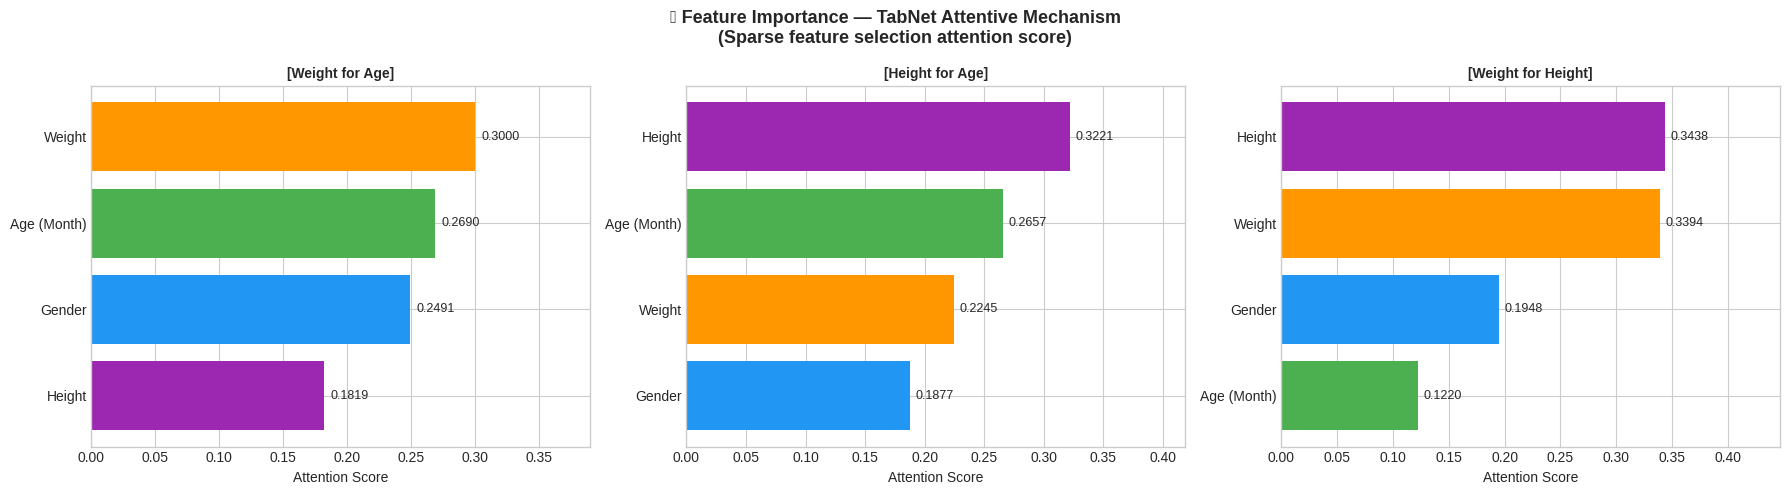

✅ Feature importance tersimpan: tabnet_feature_importance.png

📋 TABEL FEATURE IMPORTANCE
Fitur                 Weight for Age  Height for Age  Weight for Hei
--------------------------------------------------------------------
Gender                0.2491          0.1877          0.1948        
Age (Month)           0.2690          0.2657          0.1220        
Weight                0.3000          0.2245          0.3394        
Height                0.1819          0.3221          0.3438        


In [21]:
# ─── Feature Importance dari Attention Mask TabNet ──────────────────────────
# TabNet memberikan feature_importances_ dari sparse attention mask
# — semakin tinggi nilai, semakin sering fitur tersebut dipilih

all_importances = {}
for label in TARGET_COLS:
    all_importances[label] = final_models[label].feature_importances_

fig, axes = plt.subplots(1, len(TARGET_COLS), figsize=(18, 5))
fig.suptitle('🔍 Feature Importance — TabNet Attentive Mechanism\n'
             '(Sparse feature selection attention score)',
             fontsize=13, fontweight='bold')

palette = [COLORS['primary'], COLORS['accent'], COLORS['warning'], COLORS['purple']]

for ax, label in zip(axes, TARGET_COLS):
    importances = all_importances[label]
    sorted_idx  = np.argsort(importances)
    feats_sorted = [FEATURE_COLS[j] for j in sorted_idx]
    vals_sorted  = importances[sorted_idx]

    bars = ax.barh(feats_sorted, vals_sorted,
                   color=[palette[j % len(palette)] for j in sorted_idx])

    for bar, val in zip(bars, vals_sorted):
        ax.text(bar.get_width() + 0.005,
                bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', ha='left', fontsize=9)

    ax.set_title(f'[{label}]', fontweight='bold', fontsize=10)
    ax.set_xlabel('Attention Score')
    ax.set_xlim(0, max(importances) * 1.3)

plt.tight_layout()
plt.savefig('tabnet_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Feature importance tersimpan: tabnet_feature_importance.png')

print()
print('📋 TABEL FEATURE IMPORTANCE')
header = f'{"Fitur":<20}' + ''.join(f'  {c[:14]:<14}' for c in TARGET_COLS)
print(header)
print('-' * len(header))
for j, feat in enumerate(FEATURE_COLS):
    row = f'{feat:<20}'
    for label in TARGET_COLS:
        row += f'  {all_importances[label][j]:<14.4f}'
    print(row)

## 💾 11. Simpan Model

In [22]:
# ─── Simpan Model TabNet ─────────────────────────────────────────────────────
os.makedirs('saved_models', exist_ok=True)

print('💾 Menyimpan model TabNet...')
for label, model in final_models.items():
    fname = f'saved_models/tabnet_{label.replace(" ", "_").lower()}'
    model.save_model(fname)
    print(f'  ✅ [{label}] → {fname}.zip')

# Simpan hyperparameter terbaik
joblib.dump(best_params_all, 'saved_models/tabnet_best_params.joblib')
print('  ✅ Best params     → saved_models/tabnet_best_params.joblib')

# Simpan ringkasan evaluasi
eval_summary = {
    'train'      : train_results,
    'test'       : test_results,
    'best_params': best_params_all,
    'timestamp'  : datetime.now().isoformat()
}
joblib.dump(eval_summary, 'saved_models/tabnet_eval_summary.joblib')
print('  ✅ Eval summary    → saved_models/tabnet_eval_summary.joblib')

print()
print('📌 Cara load model untuk inferensi:')
print('   from pytorch_tabnet.tab_model import TabNetClassifier')
print('   model = TabNetClassifier()')
print('   model.load_model("saved_models/tabnet_weight_for_age.zip")')
print('   y_pred = model.predict(X_new)  # X_new harus sudah di-scale')

💾 Menyimpan model TabNet...
Successfully saved model at saved_models/tabnet_weight_for_age.zip
  ✅ [Weight for Age] → saved_models/tabnet_weight_for_age.zip
Successfully saved model at saved_models/tabnet_height_for_age.zip
  ✅ [Height for Age] → saved_models/tabnet_height_for_age.zip
Successfully saved model at saved_models/tabnet_weight_for_height.zip
  ✅ [Weight for Height] → saved_models/tabnet_weight_for_height.zip
  ✅ Best params     → saved_models/tabnet_best_params.joblib
  ✅ Eval summary    → saved_models/tabnet_eval_summary.joblib

📌 Cara load model untuk inferensi:
   from pytorch_tabnet.tab_model import TabNetClassifier
   model = TabNetClassifier()
   model.load_model("saved_models/tabnet_weight_for_age.zip")
   y_pred = model.predict(X_new)  # X_new harus sudah di-scale


## 📋 12. Kesimpulan

In [23]:
# ─── Kesimpulan Akhir ────────────────────────────────────────────────────────
print('╔' + '═'*72 + '╗')
print('║' + ' 📋 KESIMPULAN MODELING TABNET'.center(72) + '║')
print('╠' + '═'*72 + '╣')
print('║  Model     : TabNet (Attentive Transformer + Sparse Feature Select)  ║')
print('║  Tuning    : Optuna Bayesian Optimization — TPE Sampler, 30 trials   ║')
print('║  Task      : Multi-Output Classification (3 label terpisah)          ║')
print('║  Data      : train_smote.csv (SMOTE+Scaled) | test.csv (Orig+Scaled) ║')
print('╠' + '═'*72 + '╣')
print('║  HASIL EVALUASI AKHIR                                                ║')
print(f'║  {"Label":<28} {"Acc Train":>10} {"Acc Test":>10} {"F1W Test":>10}  ║')
print('║  ' + '-'*66 + '  ║')
for label in TARGET_COLS:
    tr  = train_results[label]['accuracy']
    te  = test_results[label]['accuracy']
    f1  = test_results[label]['f1_weighted']
    gap = abs(tr - te)
    flag = '⚠️' if gap > 0.05 else '✅'
    print(f'║  {label:<28} {tr:>10.4f} {te:>10.4f} {f1:>10.4f} {flag}  ║')
print('╠' + '═'*72 + '╣')
print('║  KEUNGGULAN TABNET:                                                  ║')
print('║  ✅ Attention mask → feature importance yang interpretable           ║')
print('║  ✅ Sparse feature selection → cocok untuk fitur antropometri        ║')
print('║  ✅ Bekerja langsung dengan numerik, tanpa one-hot encoding          ║')
print('║  ✅ Bayesian Optuna → 30 trial efisien vs ratusan Grid Search        ║')
print('╠' + '═'*72 + '╣')
print('║  OUTPUT FILES                                                        ║')
print('║  ✅ saved_models/tabnet_{label}.zip  — model per label              ║')
print('║  ✅ tabnet_confusion_matrix.png      — confusion matrix             ║')
print('║  ✅ tabnet_accuracy_curve.png        — kurva akurasi train vs test  ║')
print('║  ✅ tabnet_feature_importance.png    — feature importance attention ║')
print('║  ✅ tabnet_optuna_history.png        — optuna optimization history  ║')
print('╚' + '═'*72 + '╝')
print()
print('🎉 Modeling TabNet selesai!')
print(f'   Timestamp: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')

╔════════════════════════════════════════════════════════════════════════╗
║                      📋 KESIMPULAN MODELING TABNET                      ║
╠════════════════════════════════════════════════════════════════════════╣
║  Model     : TabNet (Attentive Transformer + Sparse Feature Select)  ║
║  Tuning    : Optuna Bayesian Optimization — TPE Sampler, 30 trials   ║
║  Task      : Multi-Output Classification (3 label terpisah)          ║
║  Data      : train_smote.csv (SMOTE+Scaled) | test.csv (Orig+Scaled) ║
╠════════════════════════════════════════════════════════════════════════╣
║  HASIL EVALUASI AKHIR                                                ║
║  Label                         Acc Train   Acc Test   F1W Test  ║
║  ------------------------------------------------------------------  ║
║  Weight for Age                   0.9678     0.9646     0.9649 ✅  ║
║  Height for Age                   0.9721     0.9588     0.9586 ✅  ║
║  Weight for Height                0.9748     0.9811 